# Digital Twins - Air Quality Simulation
**Team Members:** Frendl Krisztián & Kozicz Gergő

**Task 1: System Selection**
We have selected **Indoor Air Quality (PM2.5)** as our semester project topic.
This falls under the Monitoring, Reporting, and Verification (MRV) Digital Twin prototype category.

**Task 2: Real Observation Data**
We are using a publicly available dataset from Hugging Face containing Air Quality data:
[Karan-0123/air-quality](https://huggingface.co/datasets/karan-0123/air-quality)

**Task 3: Data Exploration and Simulation**
In this notebook, we will:
1. Load a sample of the historical dataset, including multiple environmental factors (simulated fetching for now).
2. Perform data quality checks.
3. Develop an advanced simulation model based on the Mass Balance Equation for indoor PM2.5, incorporating wind speed and humidity effects.
4. Run 6 What-If Scenarios including the Baseline.
5. Plot the scenarios individually and in a comprehensive comparison plot.

## 1. Data Loading and Initial Exploration
We generate a synthetic dataset mimicking 24 hours of outdoor PM2.5 data, along with wind speed (m/s) and relative humidity (%).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import huggingface_hub as hf_hub


df = pd.read_csv("hf://datasets/karan-0123/air-quality/air_quality.csv")

df_day = df[:24]

display(df_day.head())

,datetime,pm25,pm10,no2,co,so2,o3,temp,rh,wind,rain
0,2015-01-01 00:00:00,150.849670,257.310990,32.664554,1.204211,4.816183,1.364593,17.926895,42.058440,0.1,1.085120
1,2015-01-01 01:00:00,132.370120,254.495468,31.878915,0.860830,1.937702,1.000000,16.655569,37.960572,0.1,0.000000
2,2015-01-01 02:00:00,157.994518,256.419390,28.320158,0.074682,4.197653,2.516940,17.283748,37.412200,0.1,0.000000
3,2015-01-01 03:00:00,173.358215,269.406690,33.000651,2.563948,7.383085,1.000000,34.383131,17.713272,0.1,0.393723
4,2015-01-01 04:00:00,201.753827,335.956343,30.997890,1.326620,2.140768,1.000000,18.198381,39.903303,0.1,0.000000


## 2. Advanced Simulation Logic
We use an extended Mass Balance Equation:
$$PM_{in}(t) = PM_{in}(t-1) + \Delta t \cdot [ k(v) \cdot (PM_{out}(t) - PM_{in}(t-1)) - \gamma(h) \cdot PM_{in}(t-1) + \alpha \cdot Source - \beta \cdot Purifier ]$$

**Parameters & Functions:**
*   $PM_{in}$: Indoor air pollution.
*   $PM_{out}$: Outdoor air pollution.
*   $k(v) = k_{base} + c_w \cdot v$: Infiltration rate, where $k_{base}$ is base infiltration, $c_w$ is the wind coefficient, and $v$ is wind speed.
*   $\gamma(h) = c_h \cdot h$: Deposition rate (particles settling), which increases with high humidity $h$ (due to particle growth/heaviness).
*   $\alpha \cdot Source$: Internal pollution source (e.g., cooking, vacuum cleaning).
*   $\beta \cdot Purifier$: Air purifier efficiency (CADR).

In [2]:
def simulate_advanced_indoor_aq(data, k_base=0.1, c_w=0.05, c_h=0.001, alpha_source=0.0, beta_purifier=0.0):
    """
    Simulates indoor PM2.5 based on an advanced Mass Balance Equation.
    """
    delta_t = 1
    PM_in_initial = 15.0
    PM_in_list = [PM_in_initial]
    
    for i in range(len(data)):
        PM_in_prev = PM_in_list[-1]
        PM_out = data['pm25'].iloc[i]
        v = data['wind'].iloc[i]
        h = data['rh'].iloc[i]
        
        # Dynamic infiltration based on wind speed
        k_v = k_base + c_w * v
        
        # Dynamic deposition based on humidity
        gamma_h = c_h * h
        
        # Calculate changes
        change = delta_t * (k_v * (PM_out - PM_in_prev) - gamma_h * PM_in_prev + alpha_source - beta_purifier)
        
        # Update state
        PM_in_new = max(0, PM_in_prev + change)
        PM_in_list.append(PM_in_new)
        
    return PM_in_list[1:]

## 3. What-If Scenarios

1.  **Baseline:** Normal conditions ($k_{base}=0.1, c_w=0.05, c_h=0.001$).
2.  **Scenario A (Drafty House):** High base infiltration and wind sensitivity ($k_{base}=0.3, c_w=0.1$).
3.  **Scenario B (Humidifier ON):** Simulate high indoor humidity artificially increasing deposition (we'll boost $c_h$ to 0.005 for effect).
4.  **Scenario C (Cooking Event):** Strong internal source added.
5.  **Scenario D (Cooking + Purifier):** Internal source present, Air Purifier is running.
6.  **Scenario E (Stormy Draft):** Cooking event, purifier ON, but extreme drafty house ($k_{base}=0.5$). Testing if purifier can keep up with high infiltration.

In [3]:
# Run Scenarios
baseline = simulate_advanced_indoor_aq(df_day)
scen_A_drafty = simulate_advanced_indoor_aq(df_day, k_base=0.3, c_w=0.1)
scen_B_humidifier = simulate_advanced_indoor_aq(df_day, c_h=0.005) # Increased deposition
scen_C_cooking = simulate_advanced_indoor_aq(df_day, alpha_source=12.0)
scen_D_purifier = simulate_advanced_indoor_aq(df_day, alpha_source=12.0, beta_purifier=15.0)
scen_E_stormy = simulate_advanced_indoor_aq(df_day, k_base=0.5, c_w=0.2, alpha_source=12.0, beta_purifier=15.0)

## 4. Plotting Scenarios Individually

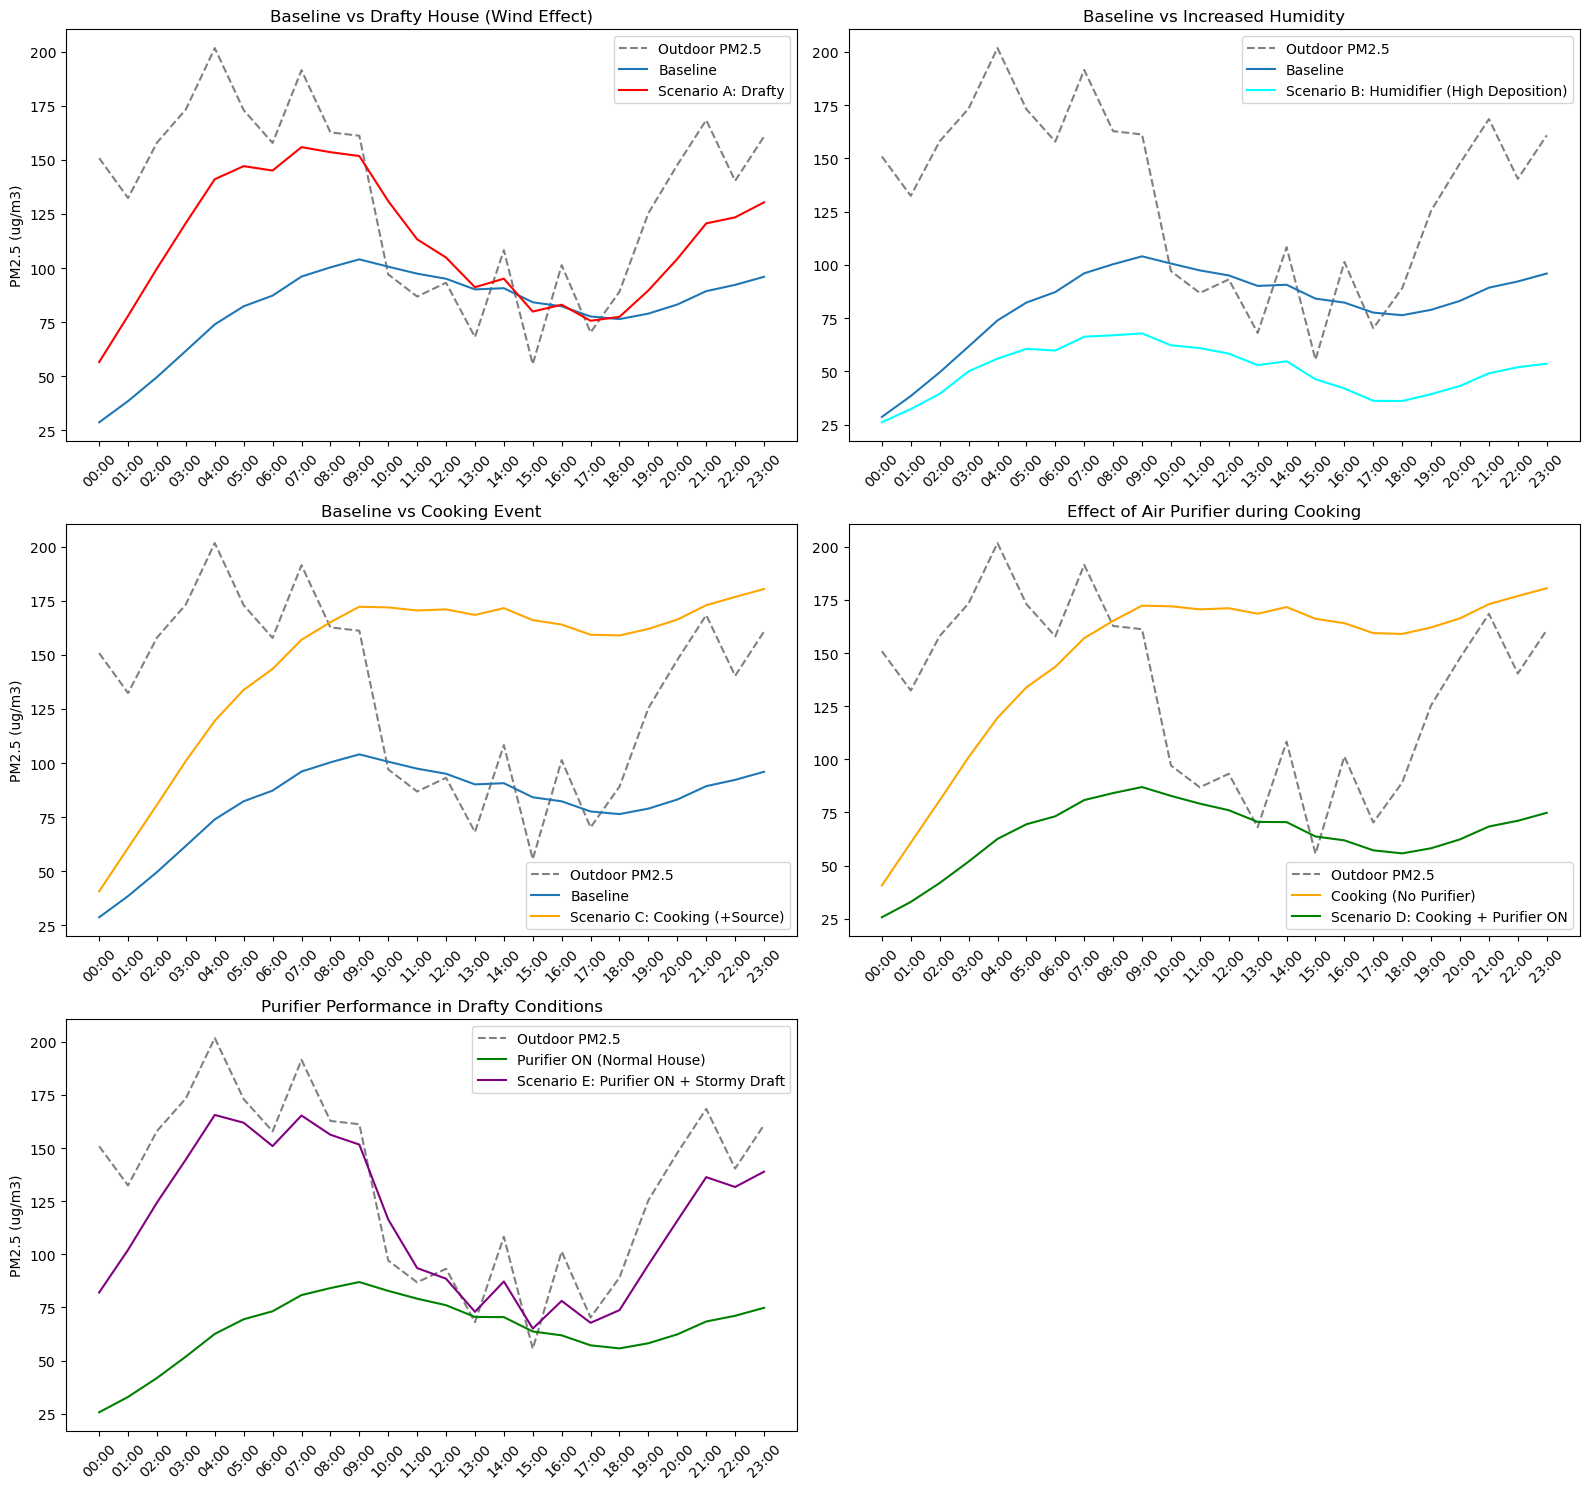

In [4]:
fig, axs = plt.subplots(3, 2, figsize=(16, 15))
time_labels = df_day['datetime'].apply(lambda x: x.split(' ')[1][:5])

# Baseline vs Drafty House
axs[0, 0].plot(time_labels, df_day['pm25'], label='Outdoor PM2.5', linestyle='--', color='gray')
axs[0, 0].plot(time_labels, baseline, label='Baseline')
axs[0, 0].plot(time_labels, scen_A_drafty, label='Scenario A: Drafty', color='red')
axs[0, 0].set_title('Baseline vs Drafty House (Wind Effect)')
axs[0, 0].set_ylabel('PM2.5 (ug/m3)')
axs[0, 0].legend()
axs[0, 0].tick_params(axis='x', rotation=45)

# Baseline vs Humidifier
axs[0, 1].plot(time_labels, df_day['pm25'], label='Outdoor PM2.5', linestyle='--', color='gray')
axs[0, 1].plot(time_labels, baseline, label='Baseline')
axs[0, 1].plot(time_labels, scen_B_humidifier, label='Scenario B: Humidifier (High Deposition)', color='cyan')
axs[0, 1].set_title('Baseline vs Increased Humidity')
axs[0, 1].legend()
axs[0, 1].tick_params(axis='x', rotation=45)

# Baseline vs Cooking Event
axs[1, 0].plot(time_labels, df_day['pm25'], label='Outdoor PM2.5', linestyle='--', color='gray')
axs[1, 0].plot(time_labels, baseline, label='Baseline')
axs[1, 0].plot(time_labels, scen_C_cooking, label='Scenario C: Cooking (+Source)', color='orange')
axs[1, 0].set_title('Baseline vs Cooking Event')
axs[1, 0].set_ylabel('PM2.5 (ug/m3)')
axs[1, 0].legend()
axs[1, 0].tick_params(axis='x', rotation=45)

# Cooking vs Purifier
axs[1, 1].plot(time_labels, df_day['pm25'], label='Outdoor PM2.5', linestyle='--', color='gray')
axs[1, 1].plot(time_labels, scen_C_cooking, label='Cooking (No Purifier)', color='orange')
axs[1, 1].plot(time_labels, scen_D_purifier, label='Scenario D: Cooking + Purifier ON', color='green')
axs[1, 1].set_title('Effect of Air Purifier during Cooking')
axs[1, 1].legend()
axs[1, 1].tick_params(axis='x', rotation=45)

# Purifier Normal vs Stormy Draft
axs[2, 0].plot(time_labels, df_day['pm25'], label='Outdoor PM2.5', linestyle='--', color='gray')
axs[2, 0].plot(time_labels, scen_D_purifier, label='Purifier ON (Normal House)', color='green')
axs[2, 0].plot(time_labels, scen_E_stormy, label='Scenario E: Purifier ON + Stormy Draft', color='purple')
axs[2, 0].set_title('Purifier Performance in Drafty Conditions')
axs[2, 0].set_ylabel('PM2.5 (ug/m3)')
axs[2, 0].legend()
axs[2, 0].tick_params(axis='x', rotation=45)

axs[2, 1].axis('off') # Hide empty subplot

plt.tight_layout()
plt.show()

## 5. Comparing the results

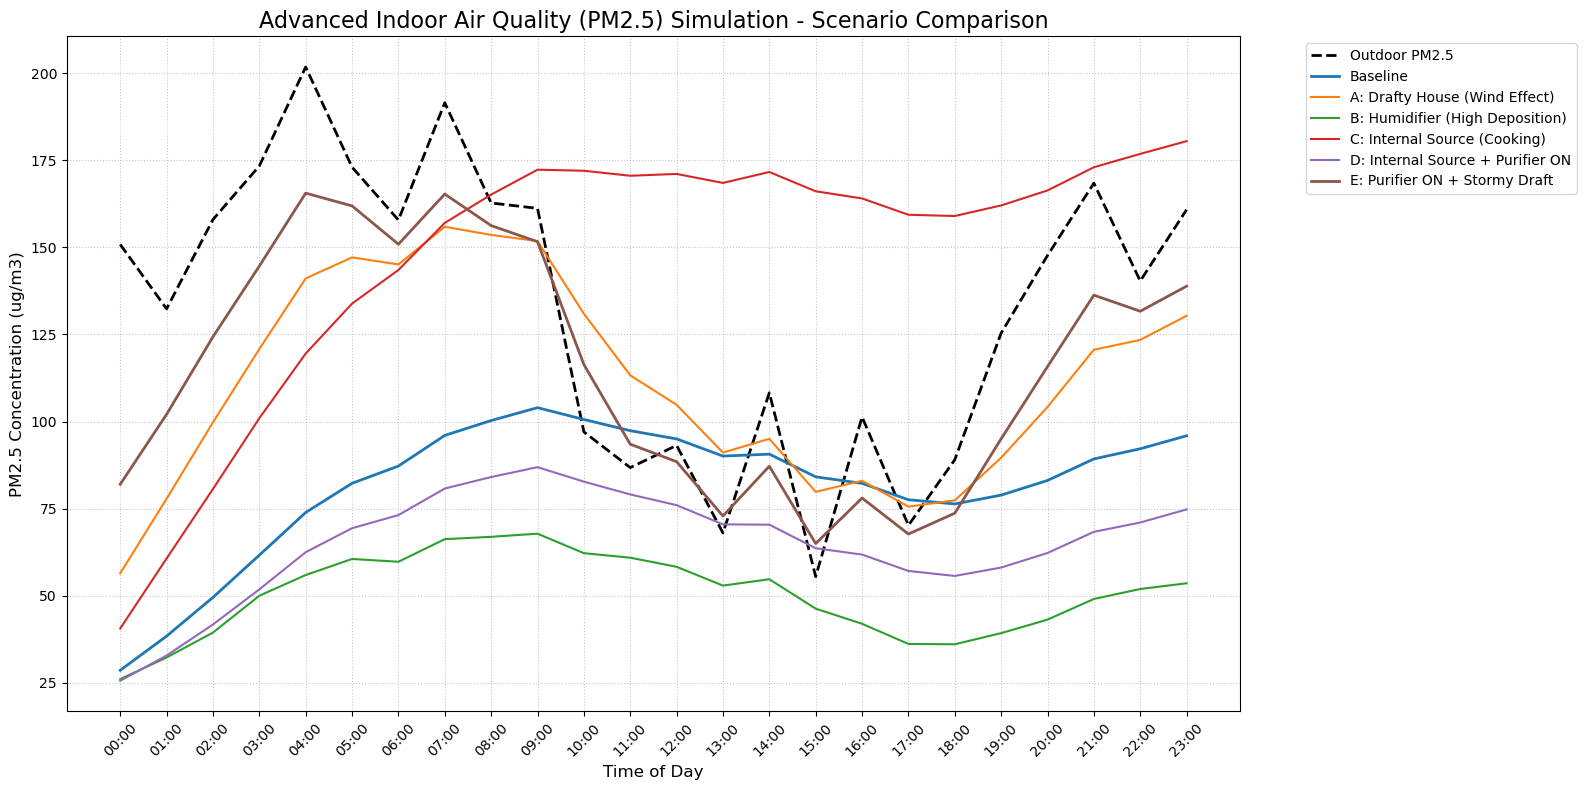

In [5]:
plt.figure(figsize=(16, 8))
plt.plot(time_labels, df_day['pm25'], label='Outdoor PM2.5', linestyle='--', color='black', linewidth=2)
plt.plot(time_labels, baseline, label='Baseline', linewidth=2)
plt.plot(time_labels, scen_A_drafty, label='A: Drafty House (Wind Effect)')
plt.plot(time_labels, scen_B_humidifier, label='B: Humidifier (High Deposition)')
plt.plot(time_labels, scen_C_cooking, label='C: Internal Source (Cooking)')
plt.plot(time_labels, scen_D_purifier, label='D: Internal Source + Purifier ON')
plt.plot(time_labels, scen_E_stormy, label='E: Purifier ON + Stormy Draft', linewidth=2)

plt.title('Advanced Indoor Air Quality (PM2.5) Simulation - Scenario Comparison', fontsize=16)
plt.xlabel('Time of Day', fontsize=12)
plt.ylabel('PM2.5 Concentration (ug/m3)', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle=':', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Simulating a month of indoor PM2.5 levels
 

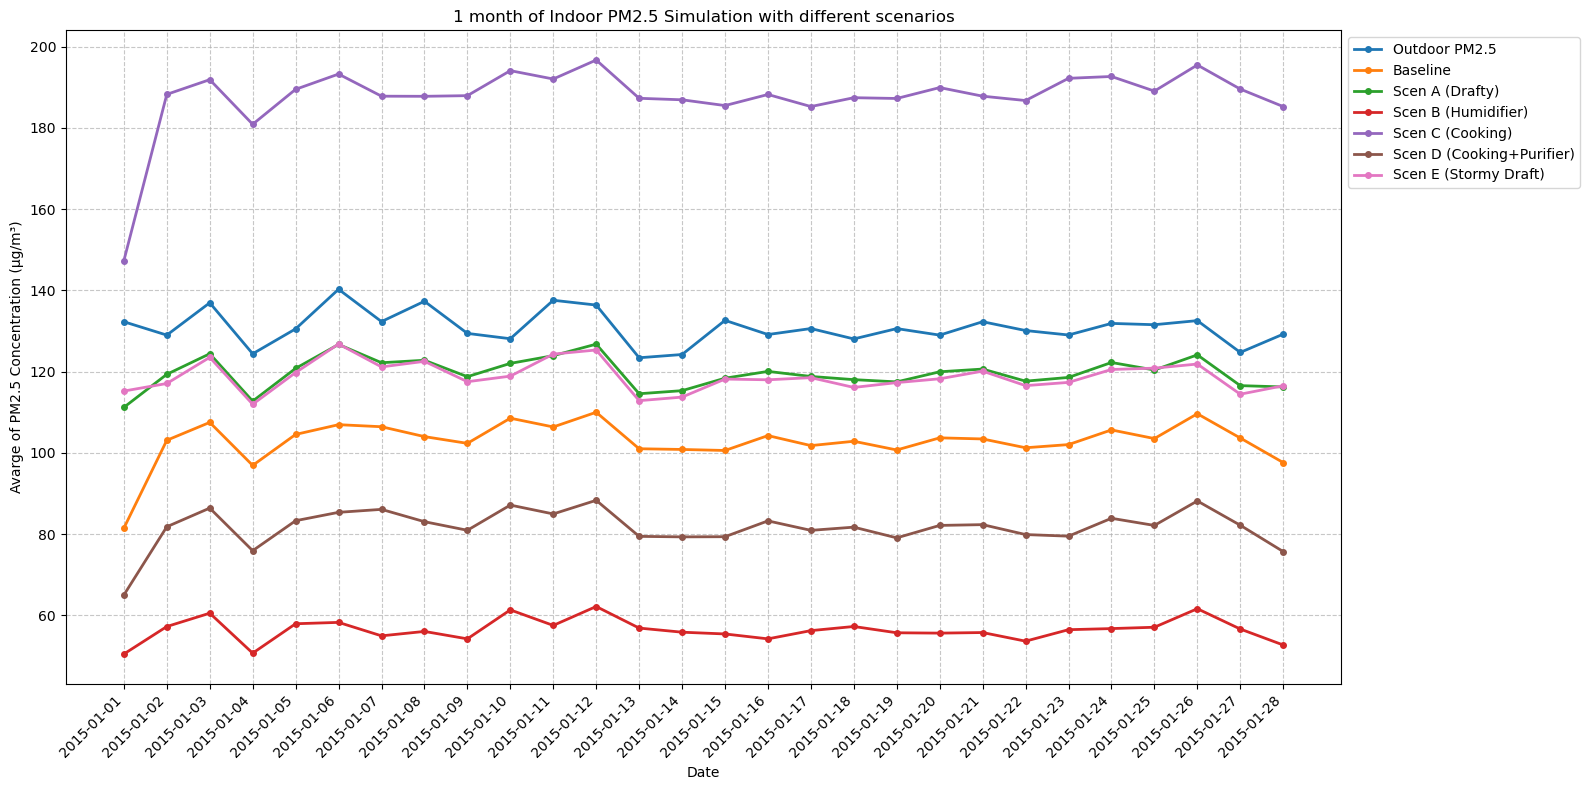

In [6]:
df_month = df[:672]


baseline = simulate_advanced_indoor_aq(df_month)
scen_A_drafty = simulate_advanced_indoor_aq(df_month, k_base=0.3, c_w=0.1)
scen_B_humidifier = simulate_advanced_indoor_aq(df_month, c_h=0.005) 
scen_C_cooking = simulate_advanced_indoor_aq(df_month, alpha_source=12.0)
scen_D_purifier = simulate_advanced_indoor_aq(df_month, alpha_source=12.0, beta_purifier=15.0)
scen_E_stormy = simulate_advanced_indoor_aq(df_month, k_base=0.5, c_w=0.2, alpha_source=12.0, beta_purifier=15.0)


results_df = pd.DataFrame({
    'Datetime': pd.to_datetime(df_month['datetime']),
    'Outdoor PM2.5 ': df_month['pm25'],  
    'Baseline': baseline,
    'Scen A (Drafty)': scen_A_drafty,
    'Scen B (Humidifier)': scen_B_humidifier,
    'Scen C (Cooking)': scen_C_cooking,
    'Scen D (Cooking+Purifier)': scen_D_purifier,
    'Scen E (Stormy Draft)': scen_E_stormy
})


daily_avg = results_df.set_index('Datetime').resample('1D').mean()


plt.figure(figsize=(16, 8))
for column in daily_avg.columns:
    
    if column == 'Outdoor PM2.5':
        plt.plot(daily_avg.index, daily_avg[column], marker='o', markersize=4, linewidth=2, linestyle='--', color='black', label=column)
    else:
        plt.plot(daily_avg.index, daily_avg[column], marker='o', markersize=4, linewidth=2, label=column)

plt.title('1 month of Indoor PM2.5 Simulation with different scenarios')
plt.xlabel('Date')
plt.ylabel('Avarge of PM2.5 Concentration (µg/m³)')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.grid(True, linestyle='--', alpha=0.7)


plt.xticks(
    ticks=daily_avg.index, 
    labels=daily_avg.index.strftime('%Y-%m-%d'), 
    rotation=45, 
    ha='right' 
)

plt.tight_layout()
plt.show()

## 6. System Design & Modelling Questions (Digital Twin Framework)

### Step 1 — Define the Modelling Purpose
* **QUESTION:** How will indoor $PM_{2.5}$ concentration ($PM_{in}$) evolve over a 24-hour period under varying outdoor air pollution, wind speed, and relative humidity conditions?
* **WHAT-IF:** What happens to indoor air quality if the building is draftier (Scenario A), a humidifier is turned on to accelerate particle settling (Scenario B), an internal pollution event like cooking occurs (Scenario C), an air purifier is operated during cooking (Scenario D), or a stormy drafty day occurs while cooking with the purifier running (Scenario E)?
* **DECISION LATER:** How should indoor air quality control devices (air purifier CADR $\beta \cdot Purifier$, humidifier) and building insulation/ventilation be operated to maintain safe indoor $PM_{2.5}$ levels while minimizing energy use and exposure?

---

### Step 2 — Define the System Boundary (Inside vs. Outside the Model)
* **INSIDE (Indoor Room / Classroom System):**
  * Indoor air pollution state: $PM_{in}(t)$
  * Dynamic infiltration process through the building envelope: $k(v) \cdot (PM_{out}(t) - PM_{in}(t-1))$
  * Gravitational particle deposition / settling process: $-\gamma(h) \cdot PM_{in}(t-1)$
  * Internal pollution generation from occupant activities: $+\alpha \cdot Source$
  * Air purifier filtration process (CADR removal): $-\beta \cdot Purifier$
* **OUTSIDE / DRIVERS:**
  * Outdoor weather and pollution drivers: Outdoor $PM_{2.5}$ ($PM_{out}$), outdoor wind speed ($v$), and relative humidity ($h$)
  * Occupant activity schedule: Cooking, vacuum cleaning, or classroom occupancy schedule ($Source$)
  * Control commands/schedules: Air purifier operation ($Purifier$) and humidifier settings
* **OUTPUT:**
  * Simulated hourly indoor $PM_{2.5}$ concentration: $PM_{in}(t)$

---

### Step 3 — Classify the Variables
* **STATE ($x$) — *What describes the system now?***
  * $PM_{in}(t)$: The current indoor $PM_{2.5}$ concentration (initialized at $PM_{in}(0) = 15.0\ \mu\text{g/m}^3$).
* **CONTROL ($u$) — *What can we deliberately change?***
  * $\beta \cdot Purifier$ (`beta_purifier`): Turning the air purifier ON/OFF or adjusting its filtration power (CADR).
  * Humidifier operation: Artificially increasing indoor humidity / deposition rate ($c_h$) to help particles settle faster.
  * $\alpha \cdot Source$ (`alpha_source`): Controlling or scheduling indoor pollution-generating activities (e.g., cooking, cleaning) or window opening.
* **DISTURBANCE ($d$) — *What affects the system but is not controlled?***
  * $PM_{out}(t)$ (`pm25`): Outdoor $PM_{2.5}$ concentration.
  * $v(t)$ (`wind`): Outdoor wind speed driving air infiltration.
  * $h(t)$ (`rh`): Ambient relative humidity affecting particle growth and settling.
* **PARAMETER ($\theta$) — *What characterizes behaviour?***
  * $k_{base}$: Base infiltration rate of the building envelope ($0.1$ in baseline).
  * $c_w$: Wind sensitivity coefficient for infiltration ($0.05$ in baseline).
  * $c_h$: Humidity coefficient for particle deposition ($0.001$ in baseline).
  * $\alpha, \beta$: Scaling coefficients for the internal pollution source and air purifier efficiency, along with the simulation time step $\Delta t = 1\text{ hour}$.
* **OBSERVATION ($y$) — *What can we measure?***
  * Sensor measurements of indoor and outdoor particulate matter ($PM_{2.5}$, $PM_{10}$), relative humidity (`rh`), temperature (`temp`), wind speed (`wind`), precipitation (`rain`), and gaseous pollutants (`no2`, `co`, `so2`, `o3`).

---

### Answers to the 6 Design Questions

1. **What is inside the system?**
   Inside the system boundary are the indoor air volume's $PM_{2.5}$ concentration ($PM_{in}$) and the internal physical mass-balance processes: outdoor-to-indoor particle infiltration through cracks/walls ($k(v) \cdot (PM_{out}(t) - PM_{in}(t-1))$), humidity-dependent particle settling/deposition ($\gamma(h) \cdot PM_{in}(t-1)$), indoor particle emission ($\alpha \cdot Source$), and active air filtration ($\beta \cdot Purifier$).

2. **What affects it from outside?**
   The system is affected from the outside by uncontrollable environmental disturbances—specifically outdoor $PM_{2.5}$ pollution ($PM_{out}$), outdoor wind speed ($v$), and relative humidity ($h$)—as well as external human drivers such as occupant activity schedules (cooking/cleaning events) and control commands for the air purifier and humidifier.

3. **Which quantity carries memory from one hour to the next?**
   The state variable **$PM_{in}$ (indoor $PM_{2.5}$ concentration)** carries the memory from one hour to the next, because each new state $PM_{in}(t)$ is computed recursively from the previous hour's concentration $PM_{in}(t-1)$ plus the net hourly change $\Delta t \cdot [\dots]$.

4. **What can we control?**
   We can deliberately control the **air purifier operation** ($\beta \cdot Purifier$), the **use of a humidifier** (modifying indoor humidity/deposition $c_h$), the **timing and intensity of indoor pollution sources** ($\alpha \cdot Source$), and over the longer term, the **airtightness/insulation of the building** ($k_{base}, c_w$).

5. **Which coefficients describe the behaviour?**
   The physical behaviour of the room is described by:
   * $k_{base}$: Base building infiltration coefficient (how drafty the room is without wind).
   * $c_w$: Wind infiltration coefficient (how strongly wind forces outdoor particles indoors, where $k(v) = k_{base} + c_w \cdot v$).
   * $c_h$: Humidity deposition coefficient (how strongly humidity accelerates particle settling, where $\gamma(h) = c_h \cdot h$).
   * $\alpha$ and $\beta$: Source emission scaling factor and air purifier removal efficiency (CADR).

6. **What can actually be measured in a real classroom (or indoor room)?**
   In a real classroom or home environment, we can directly measure:
   * **Indoor and outdoor $PM_{2.5}$ (and $PM_{10}$) concentrations** using optical laser particle sensors.
   * **Indoor and outdoor relative humidity (`rh`) and temperature (`temp`)** using digital environmental sensors.
   * **Outdoor wind speed (`wind`) and rainfall (`rain`)** via a local weather station or meteorological API.
   * **Additional air quality indicators** (`co`, `no2`, `so2`, `o3`) and **device power states** (whether the purifier/humidifier is ON or OFF), whereas internal coefficients ($k_{base}, c_w, c_h$) cannot be measured directly by a single sensor and must be estimated/calibrated from data.